In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras.datasets import imdb, boston_housing
import pickle
from keras import layers, models, optimizers, losses, metrics, regularizers, callbacks

I0000 00:00:1792493771.428814  190604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792493771.430887  190604 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792493771.886070  190604 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792493772.922551  190604 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
keras.utils.set_random_seed(67)

In [3]:
histories = {}

In [4]:
(x_tr, y_tr), _ = boston_housing.load_data()
x_tr.shape

(404, 13)

# Part 1 - IMDB Classification (Sentiment Analysis)

### 1 - Loading the IMDB dataset

In [5]:
# Question 1 : 
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)
print(f"Number of train examples : {train_data.shape[0]}, Number of test examples : {test_data.shape[0]}\n")
print(f"Type of train_data : {type(train_data)}")
print(f"First 10 words indices of the first training example (along with label) : {train_data[0][:10]}, {train_labels[0]}")
print(f"Length of the first training example : {len(train_data[0])}")

# A raw review is a list of words. Theses words are encoded as integers, where each integer represents a specific word in a dictionary. 
# (The dictionary only includes the 10,000 most frequently occurring words in the dataset)
# Then, a vector of 10,000 dimensions is created for each review. 
# Each dimension of the vector corresponds to a specific word (out of the 10000 most frequent) in the dictionary. 

Number of train examples : 25000, Number of test examples : 25000

Type of train_data : <class 'numpy.ndarray'>
First 10 words indices of the first training example (along with label) : [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65], 1
Length of the first training example : 218


### 2 - Vectorizing the data

In [6]:
# Question 2 :
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype=np.float32)
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

In [7]:
# Question 3 : 
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")
print(train_data)
print(x_train)

[list([1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32])
 list([1, 194, 1153, 194, 8255, 78, 228, 5, 6, 1463, 

In [8]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)
print(x_train[0][:20])
# we compare two independent computations: if they match, the vectorization is correct
print(f"unique words: {x_train[0].sum()}")

(25000, 10000) (25000, 10000) (25000,) (25000,)
[0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.]
unique words: 120.0


### 3 - Effect of model size

In [9]:
# Question 4 :

original_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
original_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
original_model.summary()

E0000 00:00:1792493776.056384  190604 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Question 5 : 

smaller_model = keras.Sequential([
    keras.Input(shape=(10000,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid")
    ])
smaller_model.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["acc"])
smaller_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 4)              │        40,004 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,029 (156.36 KB)

 Trainable params: 40,029 (156.36 KB)

 Non-trainable params: 0 (0.00 B)

Total params for original_model > 160.305
Total params for smaller_model > 40.029 
Question4 model has approx. 4 times more params than question5 one, heavely weighed on by the first dense layer.  

In [11]:
# Question 6 : 
history_original = original_model.fit(x_train, y_train, epochs=20, batch_size=512, validation_data=(x_test, y_test))
histories["original"] = history_original.history
history_smaller = smaller_model.fit(x_train, y_train, epochs=20, batch_size=512, validation_data=(x_test, y_test))
histories["smaller"] = history_smaller.history

pickle.dump(histories, open("histories.pkl", "wb"))

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - acc: 0.8190 - loss: 0.4717 - val_acc: 0.8738 - val_loss: 0.3546
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9031 - loss: 0.2809 - val_acc: 0.8882 - val_loss: 0.2906
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9208 - loss: 0.2200 - val_acc: 0.8899 - val_loss: 0.2772
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9336 - loss: 0.1882 - val_acc: 0.8855 - val_loss: 0.2874
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - acc: 0.9426 - loss: 0.1642 - val_acc: 0.8824 - val_loss: 0.2976
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9488 - loss: 0.1472 - val_acc: 0.8768 - val_loss: 0.3217
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - acc: 0.9547 - loss: 0.1331 - val_acc: 0.8779 - val_loss: 0.3282
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - acc: 0.9585 - loss: 0.1212 - val_acc: 0.8746 - val_loss: 0.3439
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - acc: 0.9641 - loss

In [12]:
def plot_curves(histories, names, key="val_loss"):
    plt.figure(figsize=(12, 8))
    for name in names:
        values = histories[name][key]
        epochs = range(1, len(values) + 1)
        plt.plot(epochs, values, label=name)
    plt.xlabel("Epochs")
    plt.ylabel(key)
    plt.legend()
    plt.show()

def best_epoch(histories, key="val_loss"):
    values = histories[key]
    i = int(np.argmin(values))
    return i+1, values[i]

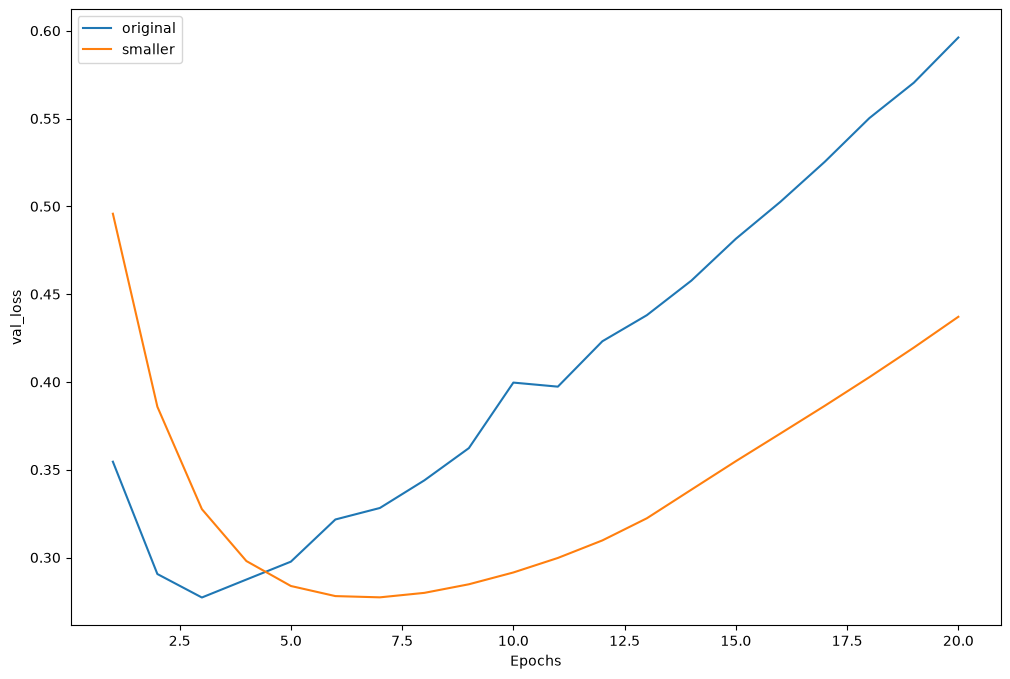

In [13]:
plot_curves(histories, ["original", "smaller"], key="val_loss")

In [14]:
for name in ["original", "smaller"]:
    ep, val = best_epoch(histories[name])
    print(f"{name}: min val_loss = {val:.4f} at epoch {ep}")

original: min val_loss = 0.2772 at epoch 3
smaller: min val_loss = 0.2773 at epoch 7


Original reaches its minimum validation loss at epoch 3 (0.2772), smaller at epoch 7 (0.2773). Both minima are almost identical, and both models overfit afterwards: the validation loss rises while the training loss keeps decreasing. Original overfits during the 17 remaining epochs, and much faster: its validation loss climbs from 0.28 to 0.60, against 0.28 to 0.44 for smaller. With 4 times fewer parameters, smaller has a lower capacity, so it learns more slowly and memorizes the training set more slowly. Since both reach the same best loss, the extra capacity of original brings no gain on this problem, only a faster overfitting.

# Part 2 - Regression : Boston Housing (K-Fold cross-validation)

### 9 - Loading the data

In [15]:
# Question 1 : 
(b_train_data, b_train_targets), (b_test_data, b_test_targets) = boston_housing.load_data()
print(f"Train set shape: {b_train_data.shape}, Test set shape : {b_test_data.shape}")
# house price is noted in k$ according to the documentation : we need to multiply the target values by 1000 to get the price in dollars
print(f"Price (target) stats :\n10 values sample : {b_train_targets[:10]} \nMin : {b_train_targets.min()*1000}$\nMax : {b_train_targets.max()*1000}$\nMean : {b_train_targets.mean()*1000:.2f}$")

Train set shape: (404, 13), Test set shape : (102, 13)
Price (target) stats :
10 values sample : [15.2 42.3 50.  21.1 17.7 18.5 11.3 15.6 15.6 14.4] 
Min : 5000.0$
Max : 50000.0$
Mean : 22395.05$


### 10 - Data normalization

In [16]:
# Question 2 :
mean = b_train_data.mean(axis=0)
std = b_train_data.std(axis=0)
b_train_data -= mean
b_train_data /= std
b_test_data -= mean
b_test_data /= std

# The statistics should not be computed on the test set, because it is supposed to be unseen data. 
# We should only use the training set to compute the statistics in order to avoid "data leakage" (i.e. accessing informations from the test set that should not normally be known).

### 11 - Model definition

In [17]:
# Question 3 : 
def build_model():
    model = keras.Sequential([
        keras.Input(shape=(b_train_data.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    return model

# Loss is addressed to the optimization process, while metrics are used to evaluate the performance of the model.
# This is why using mse is a good choice : its derivative is easy to compute, it amplifies errors, which makes it easier to optimize.
# MAE is easier to interpret : it is the average error in the same unit as the target (k$).

### 12 - K-Fold cross-validation (K=4, 100 epochs)

In [ ]:
# Question 4 : 
k = 4
num_val_samples = len(b_train_data) // k
num_epochs = 100
all_scores = []
for i in range(k):
    slice_start = i * num_val_samples
    slice_end = (i + 1) * num_val_samples
    print(f"processing fold #{i} (validation slice from {slice_start} to {slice_end})")
    val_data = b_train_data[slice_start:slice_end]
    val_targets = b_train_targets[slice_start:slice_end]
    partial_train_data = np.concatenate(
        [b_train_data[:slice_start], b_train_data[slice_end:]], axis=0) # concat of what is before the validation slice and what is after the validation slice
    partial_train_targets = np.concatenate([b_train_targets[:slice_start], b_train_targets[slice_end:]], axis=0) # same thing for targets
    model = build_model()
    model.fit(partial_train_data, partial_train_targets, epochs=num_epochs, batch_size=1, verbose=0)
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=0)
    all_scores.append(val_mae)

pickle.dump(all_scores, open("boston_q4_scores.pkl", "wb"))

# Question 5 : 
print(f"All scores : {all_scores}")
print(f"Mean score : {np.mean(all_scores)}\nStandard deviation : {np.std(all_scores)}")
# The average MAE being 2.9, it means that the model is off by 2.900$ on average when predicting house prices, which is a reasonable given the average price of houses in the dataset is 22.500$.

processing fold #0 (validation slice from 0 to 101)
processing fold #1 (validation slice from 101 to 202)
processing fold #2 (validation slice from 202 to 303)
processing fold #3 (validation slice from 303 to 404)


In [ ]:
# Question 6 : 
k = 4
num_val_samples = len(b_train_data) // k
num_epochs = 500 
all_mae_histories = []
for i in range(k):
    slice_start = i * num_val_samples
    slice_end = (i + 1) * num_val_samples
    print(f"processing fold #{i}")
    val_data = b_train_data[slice_start:slice_end]
    val_targets = b_train_targets[slice_start:slice_end]
    partial_train_data = np.concatenate(
        [b_train_data[: slice_start], b_train_data[slice_end:]], axis=0) # concat of what is before the validation slice and what is after the validation slice
    partial_train_targets = np.concatenate(
        [b_train_targets[: slice_start], b_train_targets[slice_end:]], axis=0) # same thing for targets
    model = build_model()
    history = model.fit(partial_train_data, partial_train_targets,
                        validation_data=(val_data, val_targets),
                        epochs=num_epochs, batch_size=1, verbose=0)
    all_mae_histories.append(history.history["val_mae"]) 

pickle.dump(all_mae_histories, open("boston_q6_histories.pkl", "wb"))
print(np.array(all_mae_histories).shape)  # we expect (4, 500)


processing fold #0
processing fold #1
processing fold #2
processing fold #3
